# 03 — Latent invariance

**Question.** Does a large input perturbation (noise, dropout) produce only a small change in the latent state, and does
a small latent change go with a small reconstruction change?

Per corrupted test sample, compared with the same window's clean input (no noise, all probes):
- D_latent = ‖h − h̃‖₂ / ‖h‖₂ (relative, since latent sizes differ),
- D_recon = relative L2 between the clean-input and corrupted-input reconstructions.

Latents: final hidden state of the last recurrent layer (SHRED variants, RobustSHREDv1/v2); flattened encoder latent
(SenseiverSDN, 8 × 32). SDN has no recurrent/encoder latent and gappy POD is linear — both are excluded.
**Absolute D_latent values are not strictly comparable across architectures**; within-model relationships are the result.

**Setup.** Nektar cylinder wake (Raissi PINN data), 200 snapshots × 5000 grid points (100 × 50, x∈[1,8], y∈[−2,2]).
Target: both velocity components, state = [u; v] (10 000 values). N = 8 probes, each reading u and v at one grid point,
placed by block-QR pivoting over grid points on the rank-16 POD basis of the training data. Lags = 10, interleaved
80/10/10 window split, seeds {0, 1, 2} (seed changes split, probe locations, POD basis and init). GRU for all recurrent models.

**Corruption (identical for all methods).** Gaussian noise σ = 0.05 × per-channel training std, added in unscaled
units (fresh per batch in training; fixed seeded realisation at test). Dropout: each probe fails with probability p for
the whole lag window (both channels), at least one probe survives. Training p = 0.3 for "-dropout" and masked models.
Test: p = 0 and p = 0.3, 10 fixed draws per test window, shared across methods (and gappy POD).
Zero-fill methods see 0 in the min-max scaled input space (= training minimum of that probe, not "no signal").
Masked methods (SenseiverSDN, RobustSHREDv1/v2) exclude failed probes from attention (key padding mask + learned null
token); gappy POD solves least squares with the available rows, rank r' = min(16, 2·available), clipped to the
training range. Early stopping uses a validation set corrupted like the method's training data.

In [1]:
RUN_TRAINING = False   # True: train runs that are not cached yet (cached runs are skipped)
QUICK = False          # True: 1 seed, 20 epochs, separate cache dir (smoke test)

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from get_shredded import meeting_plots as mp
from get_shredded.meeting_runner import (
    LATENT_METHODS, load_arrays, load_config, load_results, load_seed_info, prepare_seed, run_all,
)

TIER_A = ["SHRED-noise", "SHRED-dropout", "SDN-noise", "SDN-dropout",
          "SenseiverSDN", "RobustSHREDv1", "RobustSHREDv2", "GappyPOD"]
TIER_B = ["SHRED-dropout+mask"]
METHODS = TIER_A + TIER_B
OVERRIDES = ["meeting.methods=[" + ",".join(METHODS) + "]"]
if QUICK:
    OVERRIDES += ["meeting.seeds=[0]", "train.epochs=20", "outputs.root=outputs/meeting_2026-10-14_quick"]
cfg = load_config(OVERRIDES)
ROOT = cfg.outputs.root
if RUN_TRAINING:
    run_all(cfg)
results = load_results(ROOT)
print(f"{len(results)} completed runs in {ROOT}")

27 completed runs in outputs/meeting_2026-10-14


In [2]:
LAT = [m for m in METHODS if m in LATENT_METHODS]
print(LAT)

['SHRED-noise', 'SHRED-dropout', 'SenseiverSDN', 'RobustSHREDv1', 'RobustSHREDv2', 'SHRED-dropout+mask']


## D_latent vs number of failed probes (p = 0.3); p = 0 (noise only) shown at k = 0 as open markers

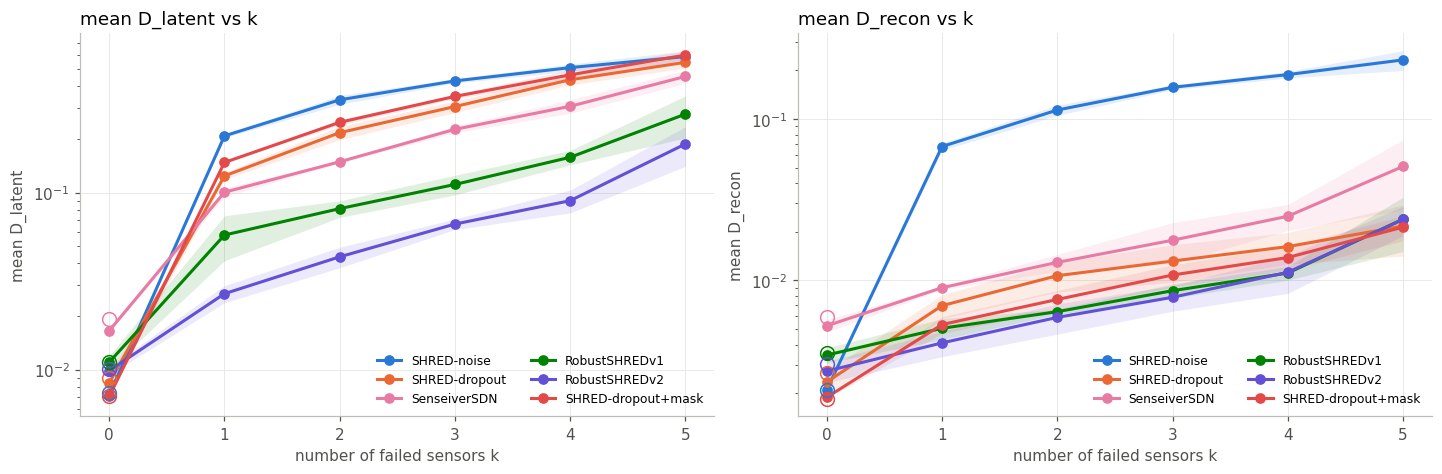

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
for ax, key, label in [(axes[0], "d_latent", "mean D_latent"), (axes[1], "d_recon", "mean D_recon")]:
    mp.plot_by_k(ROOT, results, LAT, f"p0.3_{key}", label, f"{label} vs k", ax=ax, logy=True)
    for m in LAT:
        vals, _ = mp.per_sample(ROOT, results, m, f"p0_{key}")
        if vals:
            ax.plot([0], [np.mean([v.mean() for v in vals])], marker="o", markersize=9, markerfacecolor="none",
                    color=mp.METHOD_COLORS[m], linestyle="none")
mp.save(fig, ROOT, "03_latent_by_k"); plt.show()

**Takeaway:** D_latent grows with k for every model. At p = 0.3, RobustSHREDv2 has the smallest relative latent change (mean 0.060), then RobustSHREDv1 (0.10), SenseiverSDN (0.19), SHRED-dropout (0.26), SHRED-dropout+mask (0.30), SHRED-noise (0.36). D_recon does not follow the same ranking: SHRED-dropout's latent moves ≈ 4× more than RobustSHREDv2's, but its D_recon is only ≈ 1.6× larger (0.012 vs 0.0077), and SHRED-dropout+mask has a large D_latent yet a D_recon of 0.0095.

## D_latent vs D_recon per sample

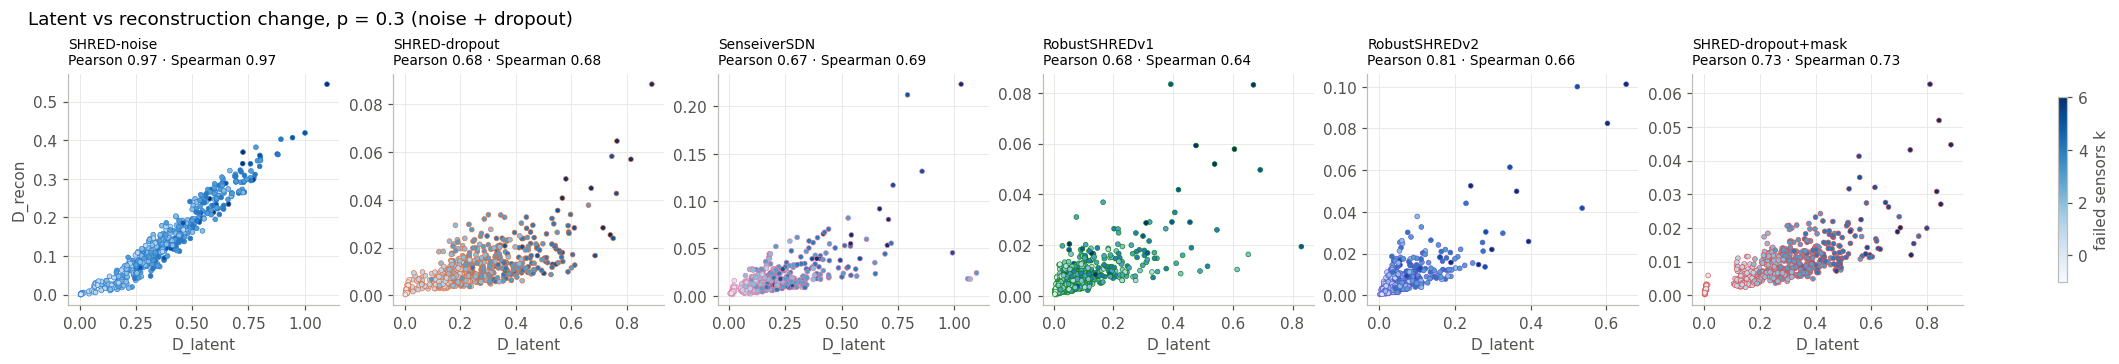

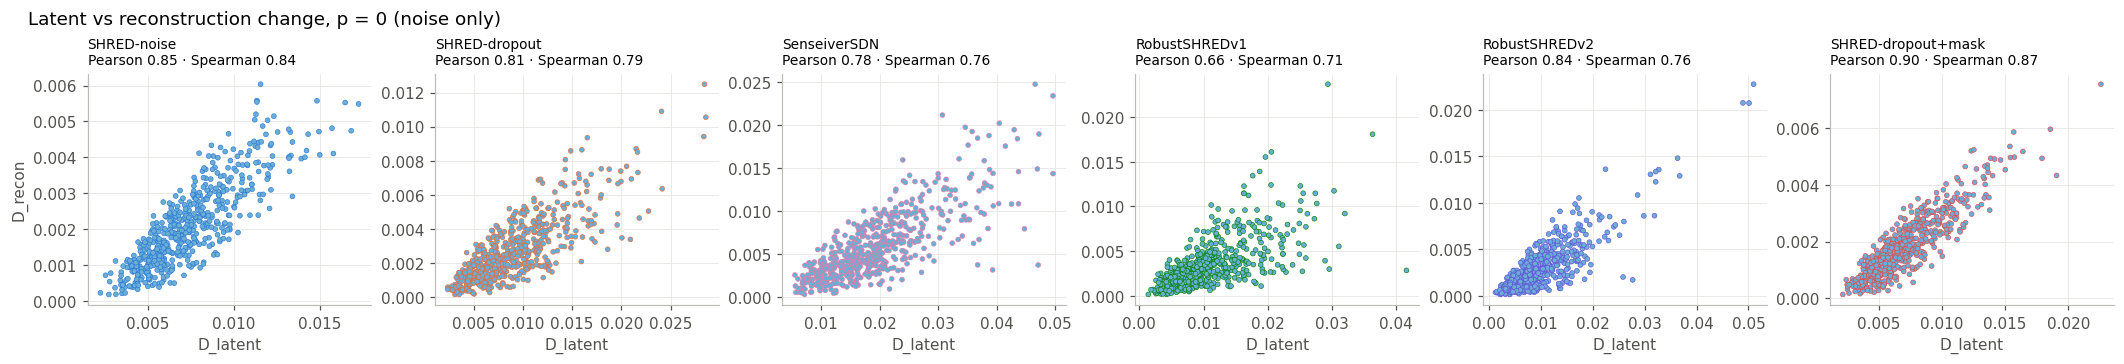

| Model | cond | mean D_latent | mean D_recon | Pearson r | Spearman ρ | n |
|---|---|---:|---:|---:|---:|---:|
| SHRED-noise | p0 | 0.0074 | 0.0021 | 0.85 | 0.84 | 570 |
| SHRED-dropout | p0 | 0.0090 | 0.0027 | 0.81 | 0.79 | 570 |
| SenseiverSDN | p0 | 0.0194 | 0.0060 | 0.78 | 0.76 | 570 |
| RobustSHREDv1 | p0 | 0.0110 | 0.0036 | 0.66 | 0.71 | 570 |
| RobustSHREDv2 | p0 | 0.0102 | 0.0030 | 0.84 | 0.76 | 570 |
| SHRED-dropout+mask | p0 | 0.0071 | 0.0018 | 0.90 | 0.87 | 570 |
| SHRED-noise | p0.3 | 0.3597 | 0.1292 | 0.97 | 0.97 | 570 |
| SHRED-dropout | p0.3 | 0.2628 | 0.0120 | 0.68 | 0.68 | 570 |
| SenseiverSDN | p0.3 | 0.1935 | 0.0170 | 0.67 | 0.69 | 570 |
| RobustSHREDv1 | p0.3 | 0.1025 | 0.0082 | 0.68 | 0.64 | 570 |
| RobustSHREDv2 | p0.3 | 0.0603 | 0.0077 | 0.81 | 0.66 | 570 |
| SHRED-dropout+mask | p0.3 | 0.2953 | 0.0095 | 0.73 | 0.73 | 570 |

In [4]:
for cond in ("p0.3", "p0"):
    fig = mp.plot_latent_scatter(ROOT, results, LAT, cond)
    mp.save(fig, ROOT, f"03_scatter_{cond}"); plt.show()
rows = ["| Model | cond | mean D_latent | mean D_recon | Pearson r | Spearman ρ | n |", "|---|---|---:|---:|---:|---:|---:|"]
for cond in ("p0", "p0.3"):
    for m, c in mp.latent_correlations(ROOT, results, LAT, cond).items():
        rows.append(f"| {m} | {cond} | {c['d_latent_mean']:.4f} | {c['d_recon_mean']:.4f} | {c['pearson']:.2f} | {c['spearman']:.2f} | {c['n']} |")
display(Markdown("\n".join(rows)))

**Takeaway:** For SHRED-noise, D_recon tracks D_latent almost linearly (Pearson 0.97): latent changes go straight into the output. For dropout-trained models the correlation is weaker (0.64–0.81) and D_recon is an order of magnitude smaller at the same D_latent, i.e. their decoders are insensitive to the latent directions that dropout perturbs. At p = 0 (noise only) all models have D_latent ≈ 0.007–0.019 and D_recon ≈ 0.002–0.006.

## Does "large input perturbation → small latent change → small reconstruction degradation" hold?

**Takeaway:** - **SHRED-noise:** no — large latent change (0.36) and large reconstruction change (0.13), tightly coupled.
- **SHRED-dropout / SHRED-dropout+mask:** the latent changes a lot (0.26 / 0.30) but the reconstruction barely changes (0.012 / 0.0095): robustness comes from the decoder ignoring the perturbed latent directions, not from an invariant latent.
- **RobustSHREDv1 / v2:** closest to the hypothesis — smallest latent changes (0.10 / 0.06) and the smallest reconstruction changes (0.0082 / 0.0077); but their final p = 0.3 errors are no better than SHRED-dropout's.
- **SenseiverSDN:** intermediate latent change (0.19), largest D_recon among the dropout-trained models (0.017).

So a small latent change is sufficient but not necessary for a small reconstruction change here. Absolute D_latent is not strictly comparable across architectures.